# A tour of Tensorgami

The small reference models of the test suite (`tests/models/`), one per model family, each in
the views that suit it. Every figure is drawn automatically from the PyTorch model:
`tg.draw(model, example_input, …)`.

In [1]:
import sys

sys.path.insert(0, "../tests")  # the reference models live with the tests

from models import REFERENCE

import tensorgami as tg


def model(name):
    """A reference model and an example input for it."""
    make, example = REFERENCE[name]
    return make(), example()


print(sorted(REFERENCE))

['cgan_discriminator', 'cgan_generator', 'cnn', 'convlstm', 'lstm', 'pix2pix_discriminator', 'pix2pix_generator', 'transformer', 'vae']


## CNN with residual blocks

Two identical residual blocks fold into one frame marked ×2; the skip connection runs beside
the block's main path. The volume view draws the feature maps as tensors.

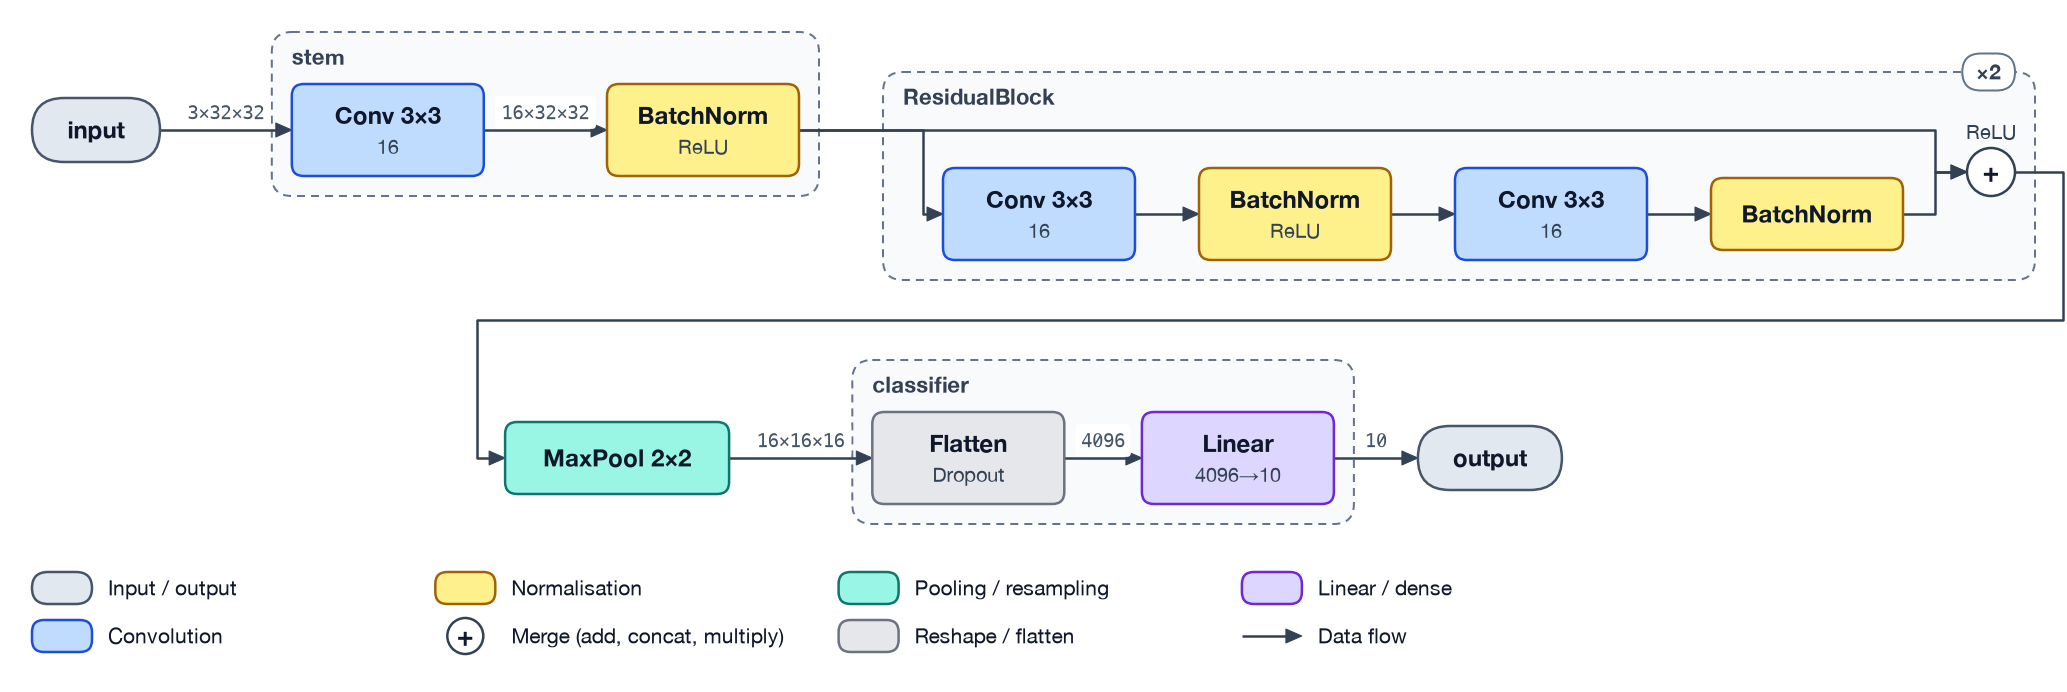

In [2]:
cnn, image = model("cnn")
tg.draw(cnn, image)

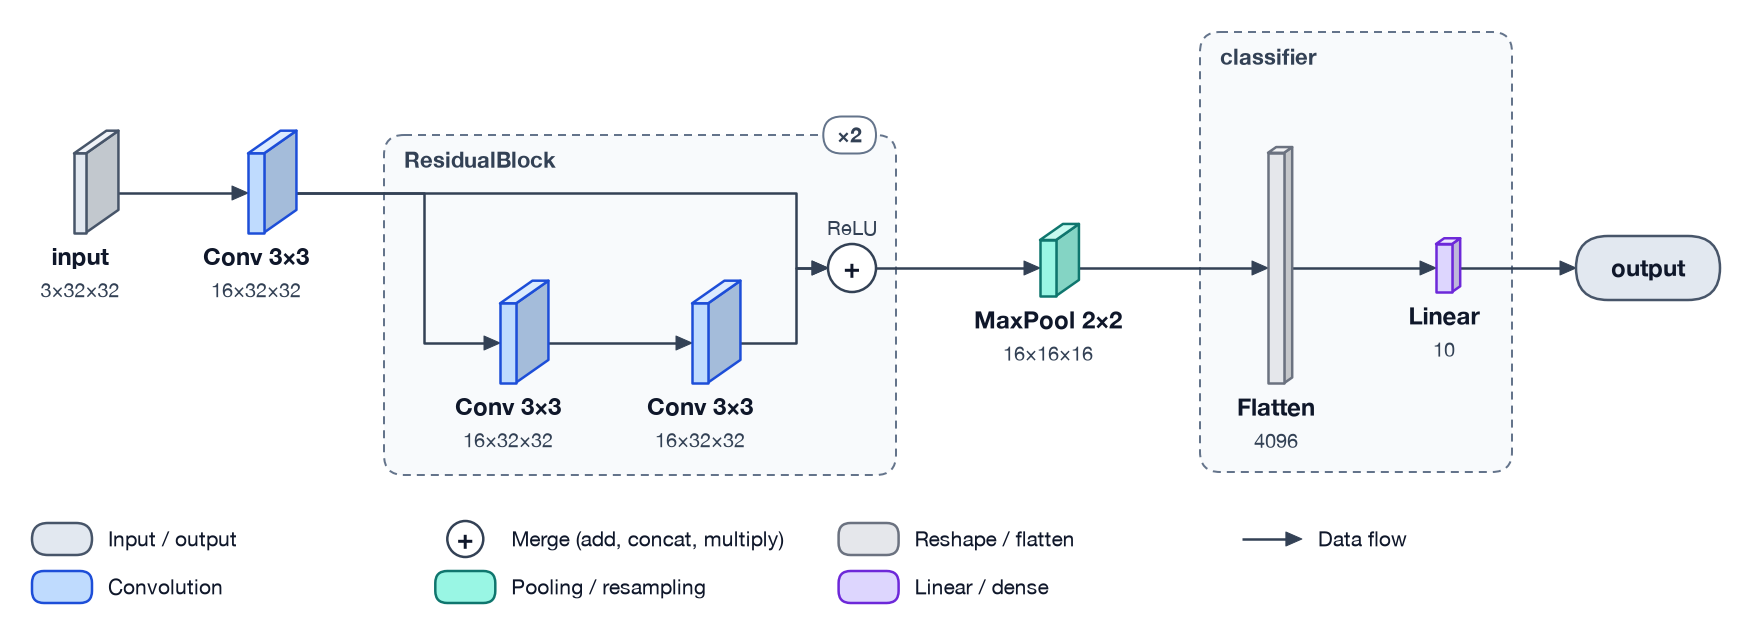

In [3]:
tg.draw(cnn, image, view="volume")

## LSTM classifier

A fused `nn.LSTM` is one call, so the block view shows one box; `view="unrolled"` draws it as
a grid: a column per time step, a row per layer, the inputs x_t below, the state passed along
each row (long sequences: the first steps, "⋯", the last).

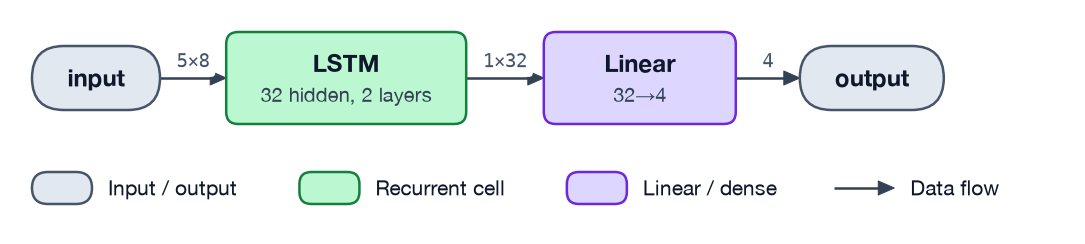

In [4]:
lstm, sequence = model("lstm")
tg.draw(lstm, sequence)

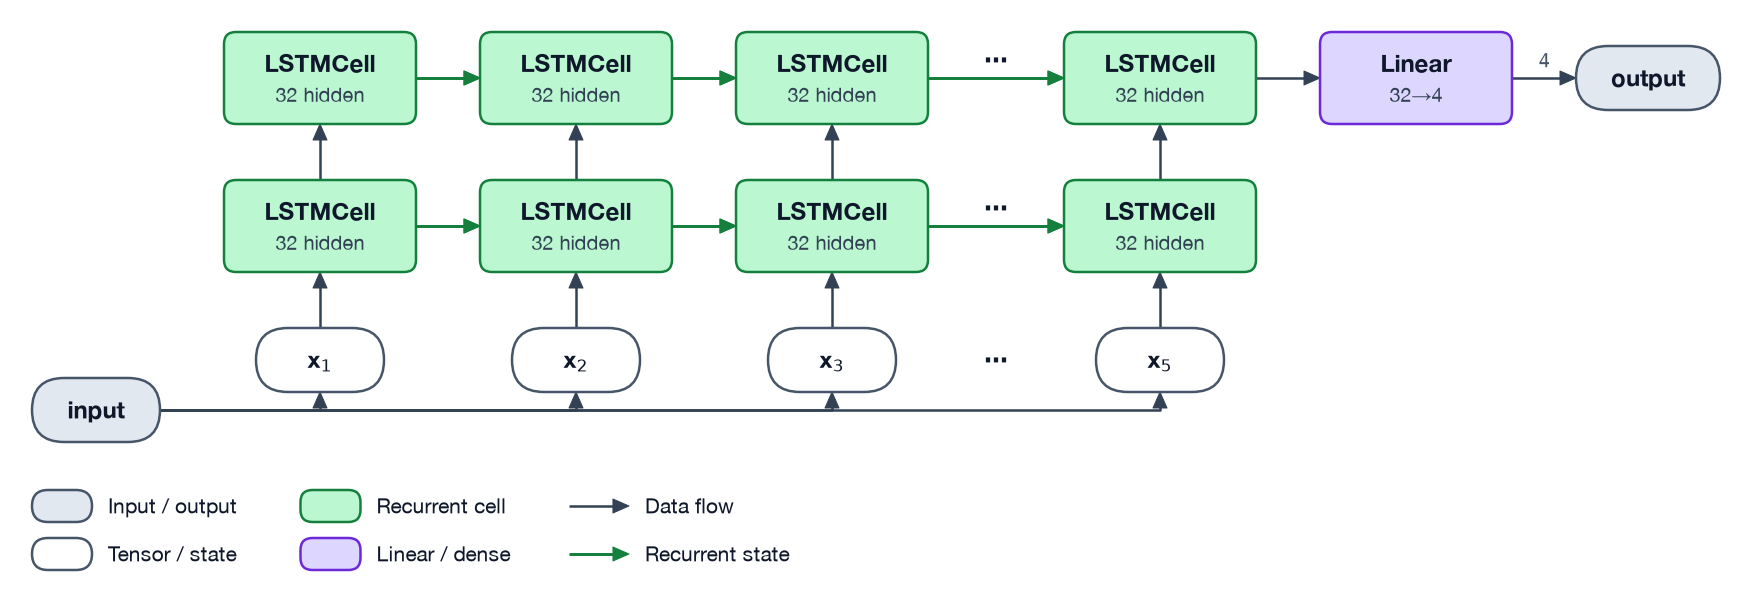

In [5]:
tg.draw(lstm, sequence, view="unrolled")

## ConvLSTM

The cells are called in a Python loop over time, so `view="auto"` (the default) unrolls them;
`view="block"` draws each layer once with its recurrent state loops (■ = one-step delay).

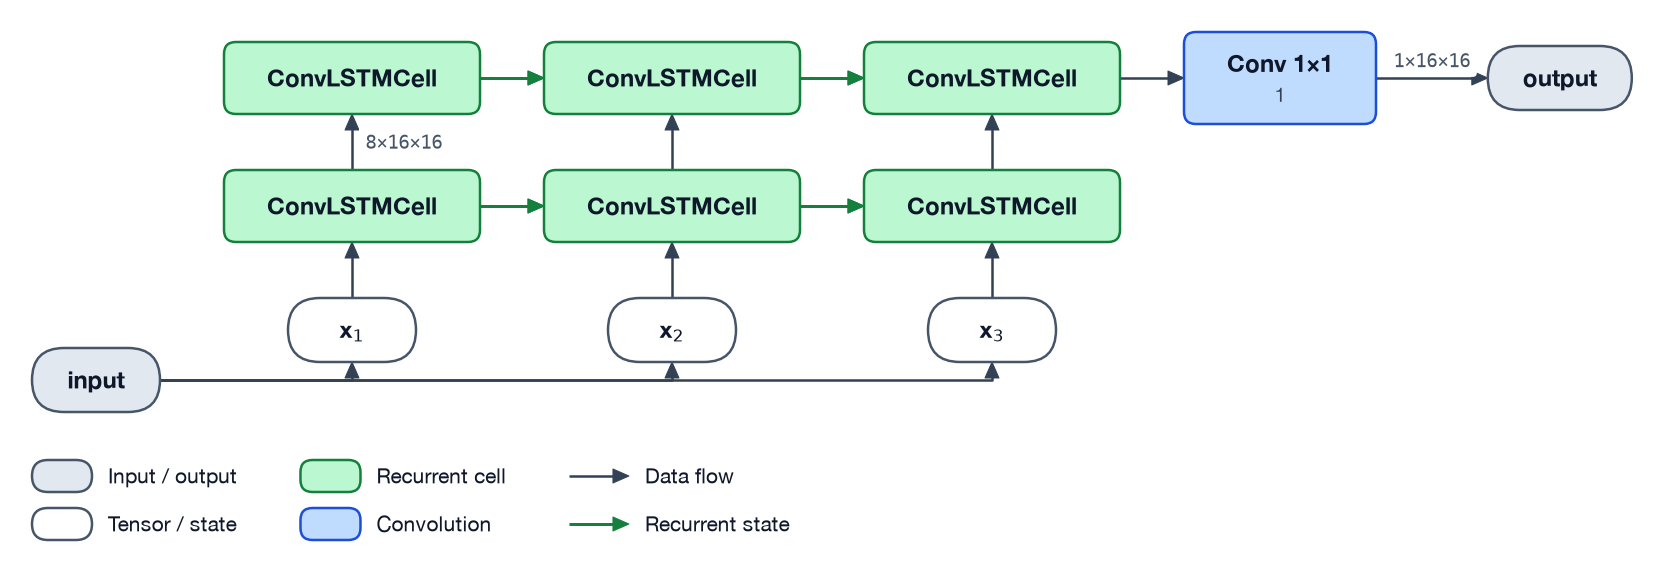

In [6]:
convlstm, frames = model("convlstm")
tg.draw(convlstm, frames)

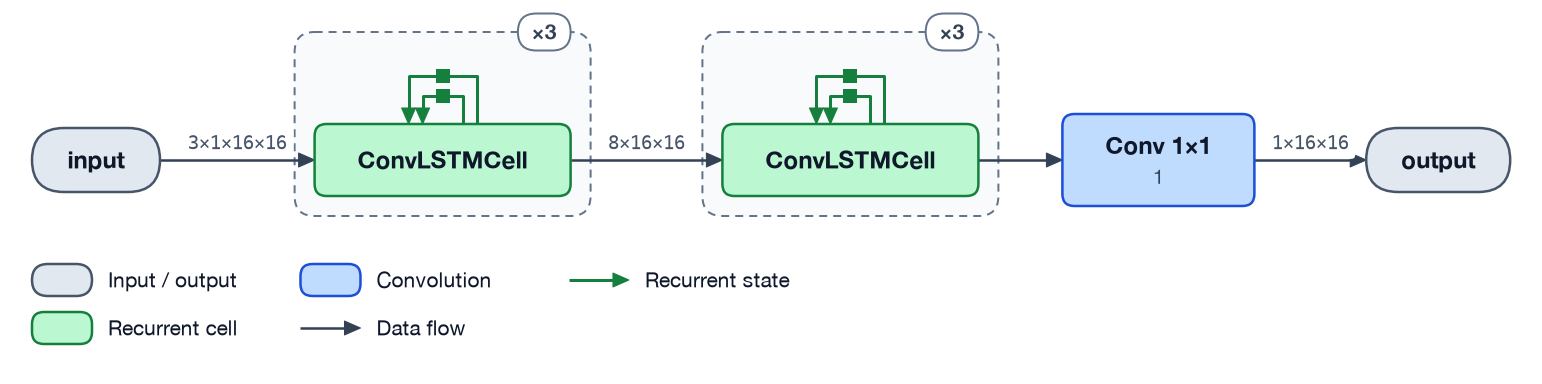

In [7]:
tg.draw(convlstm, frames, view="block")

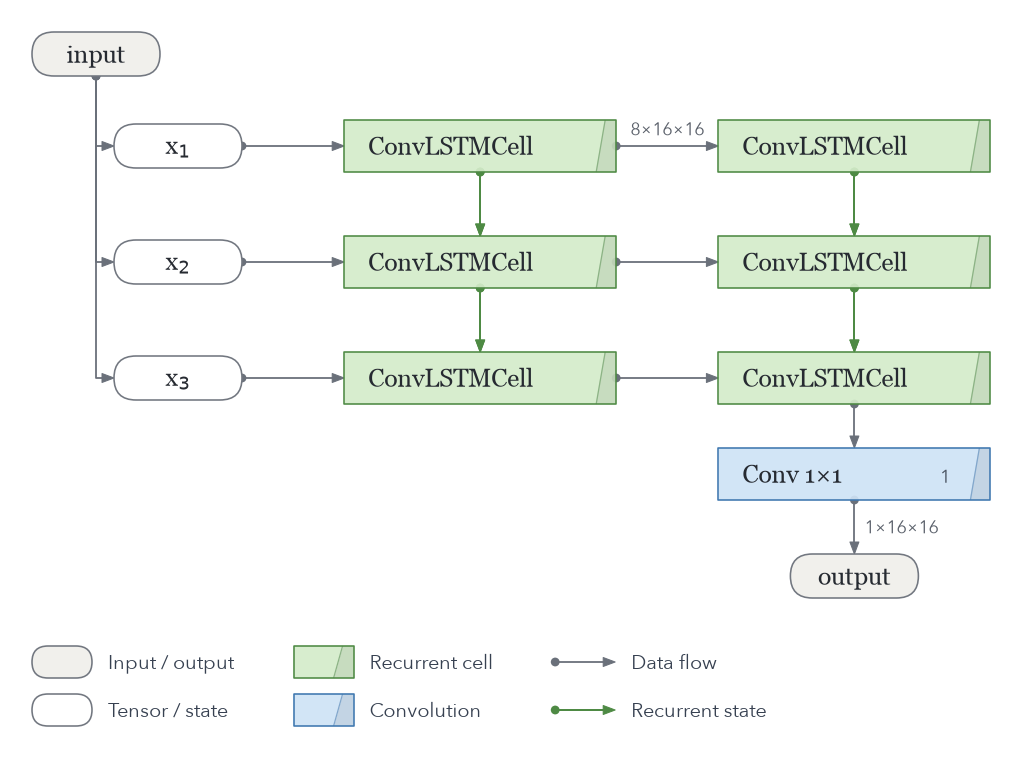

In [8]:
tg.draw(convlstm, frames, style="origami-extended")  # the grid turned: time runs down

## Inside a cell

`view="cell"` draws the recurrent cell itself, as its gates. The ConvLSTM's cell is recognised
as an LSTM from its traced operations (its gates are a convolution); a fused `nn.LSTM` is
drawn from its settings.

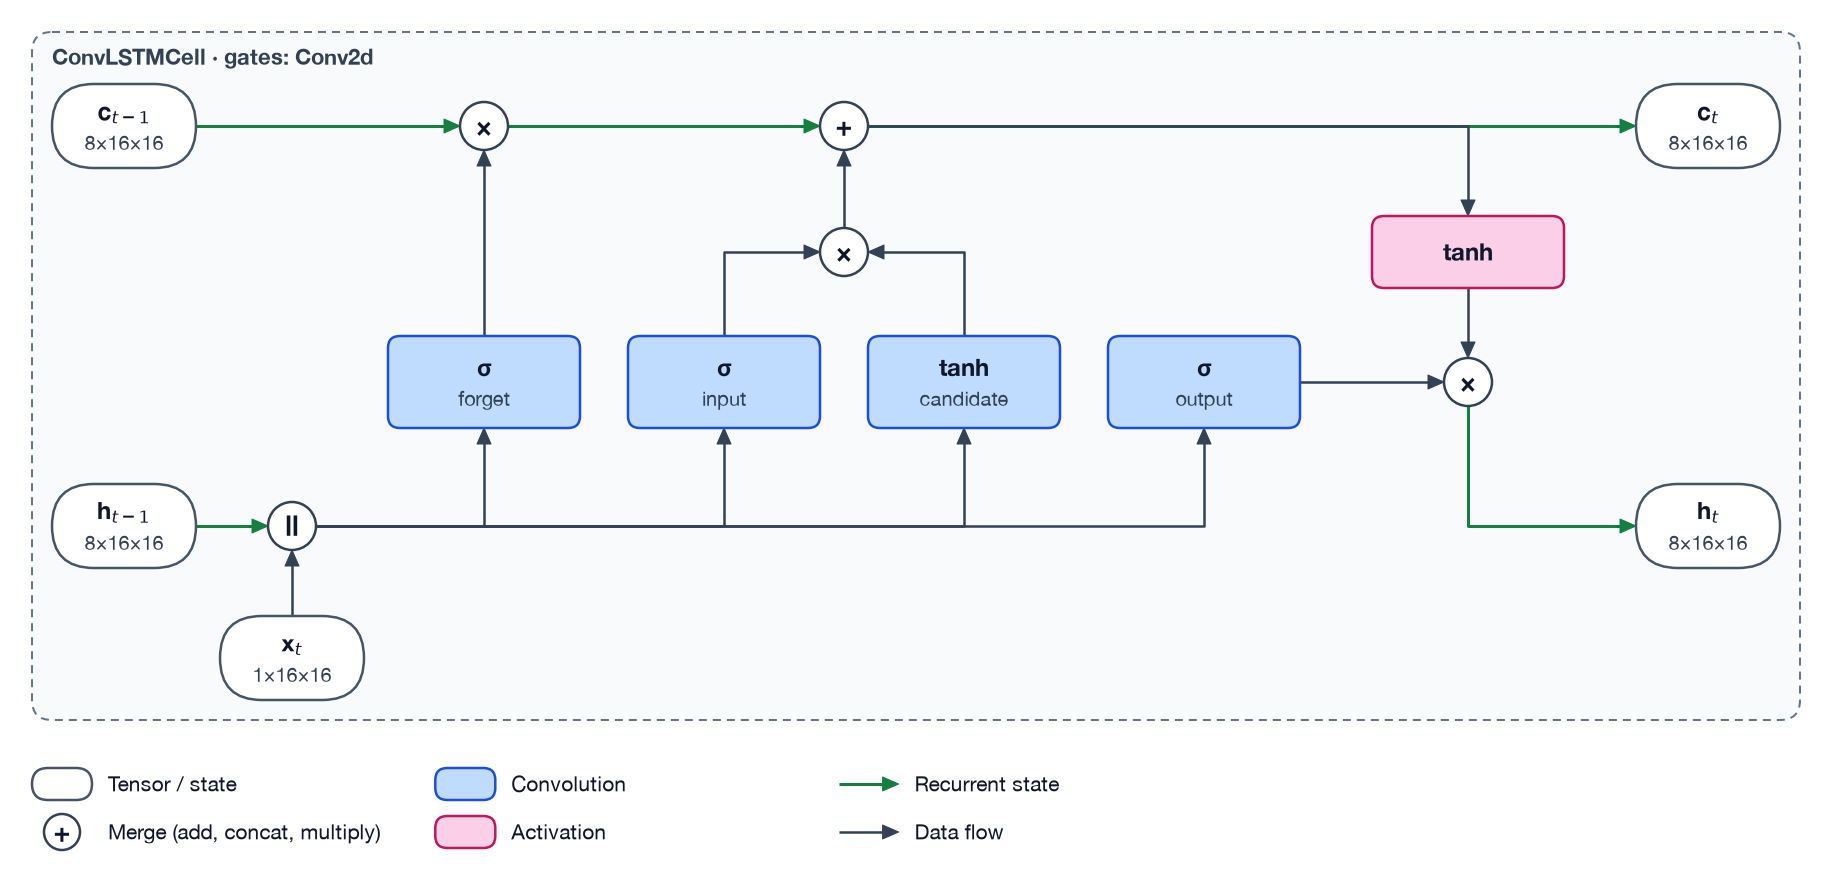

In [9]:
tg.draw(convlstm, frames, view="cell")

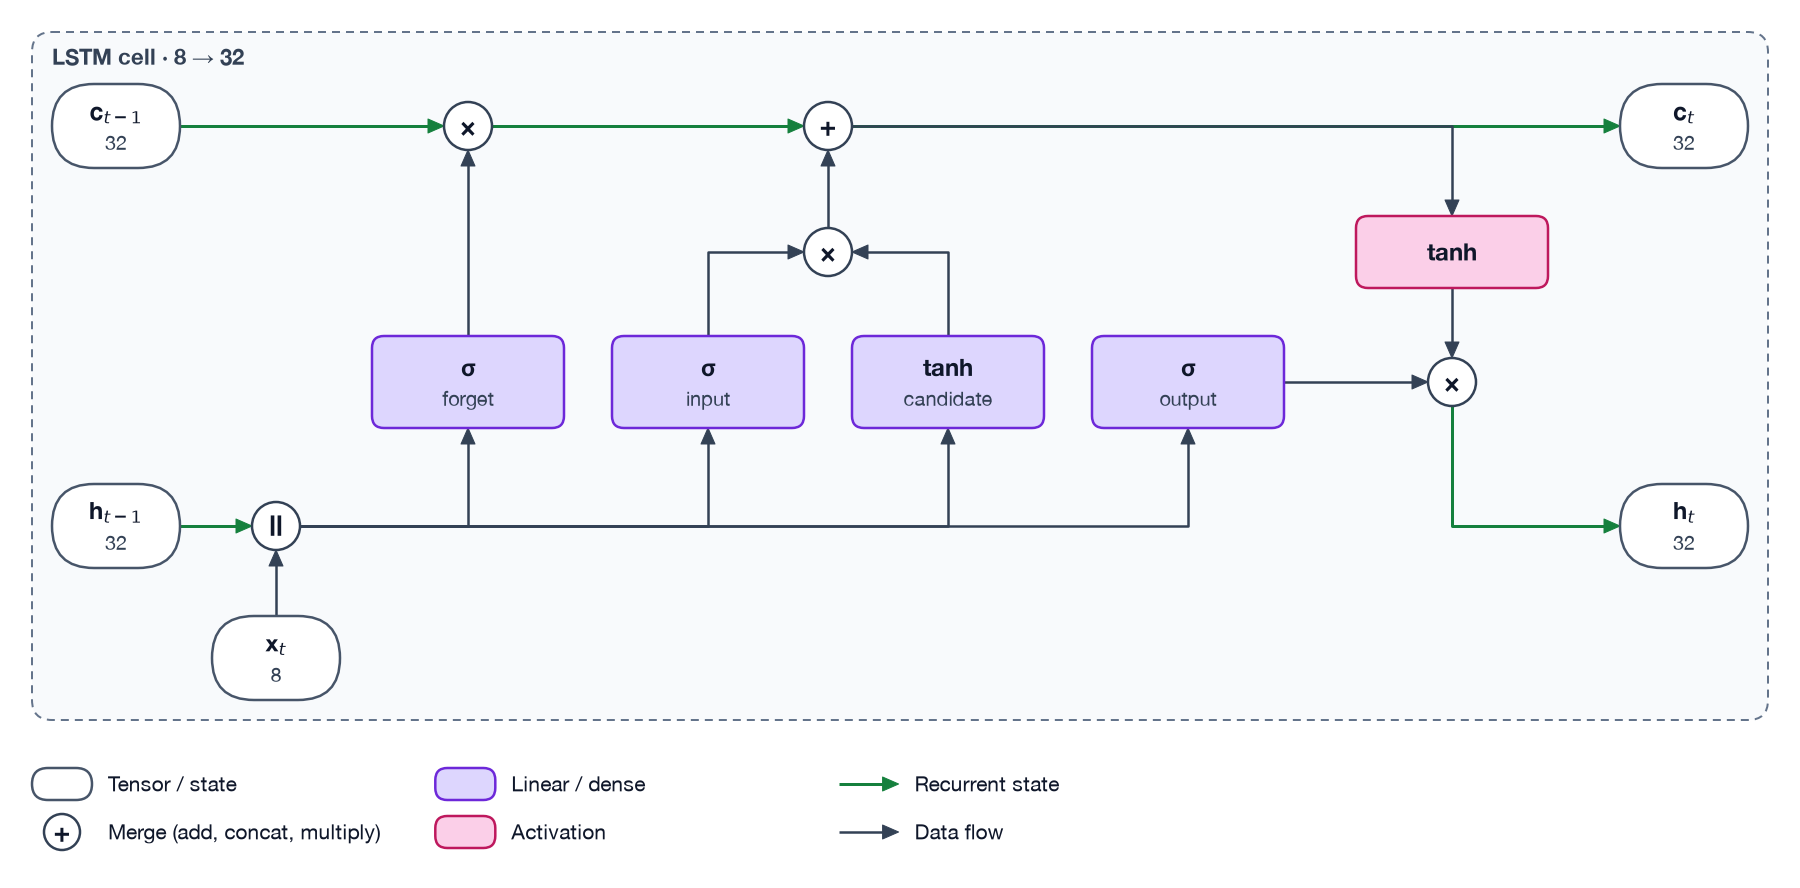

In [10]:
tg.draw(lstm, sequence, view="cell")

## VAE

The noise ε is a dashed source with a dotted arrow, kept apart from μ (the reparameterisation
trick).

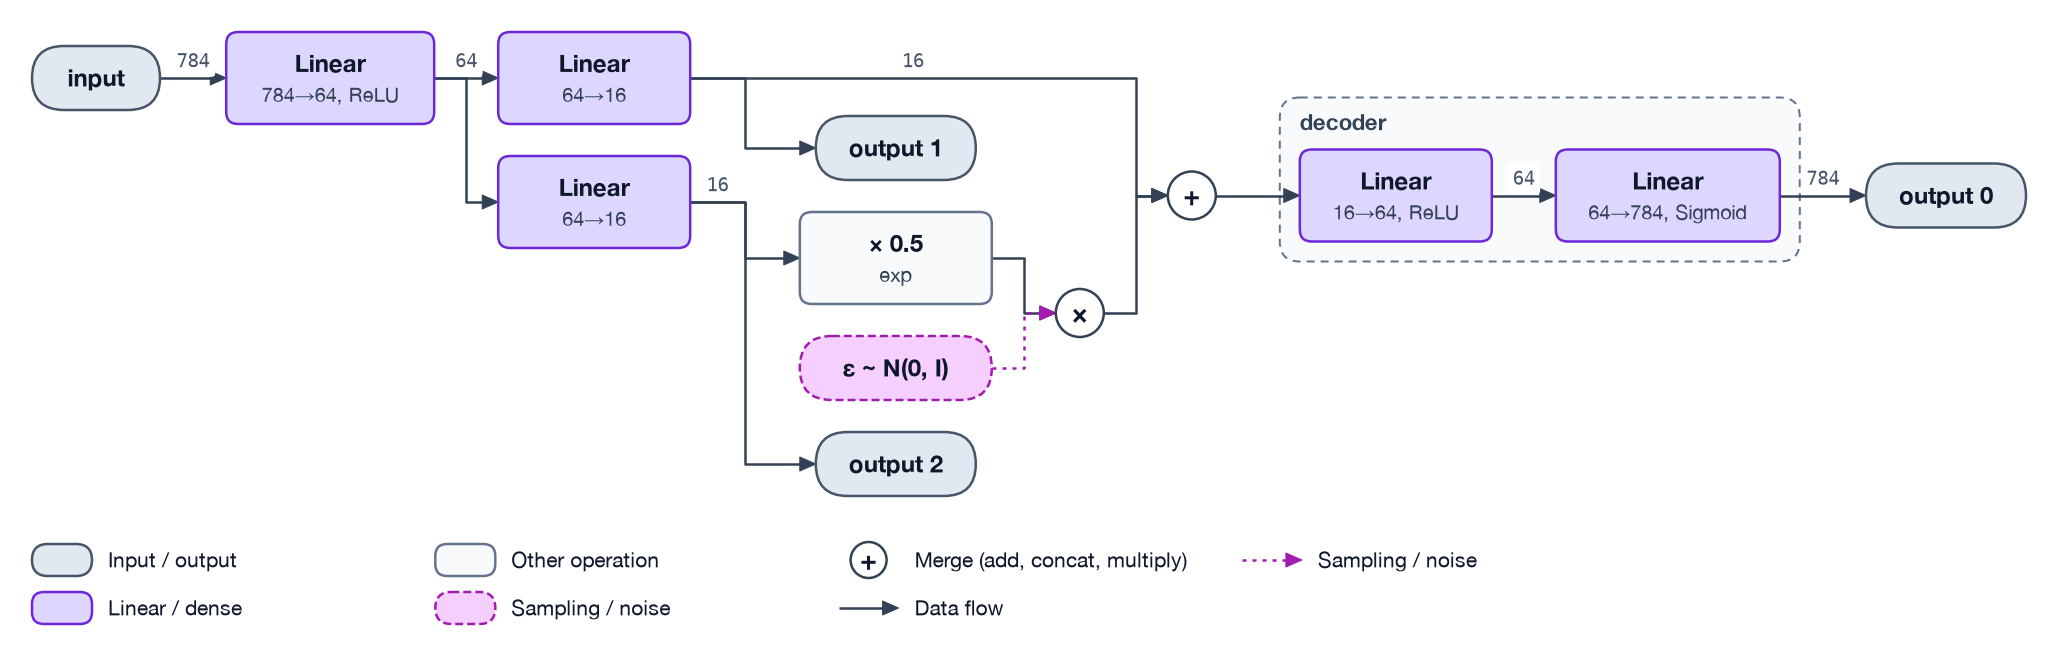

In [11]:
vae, digits = model("vae")
tg.draw(vae, digits)

## Conditional GAN: generator and discriminator

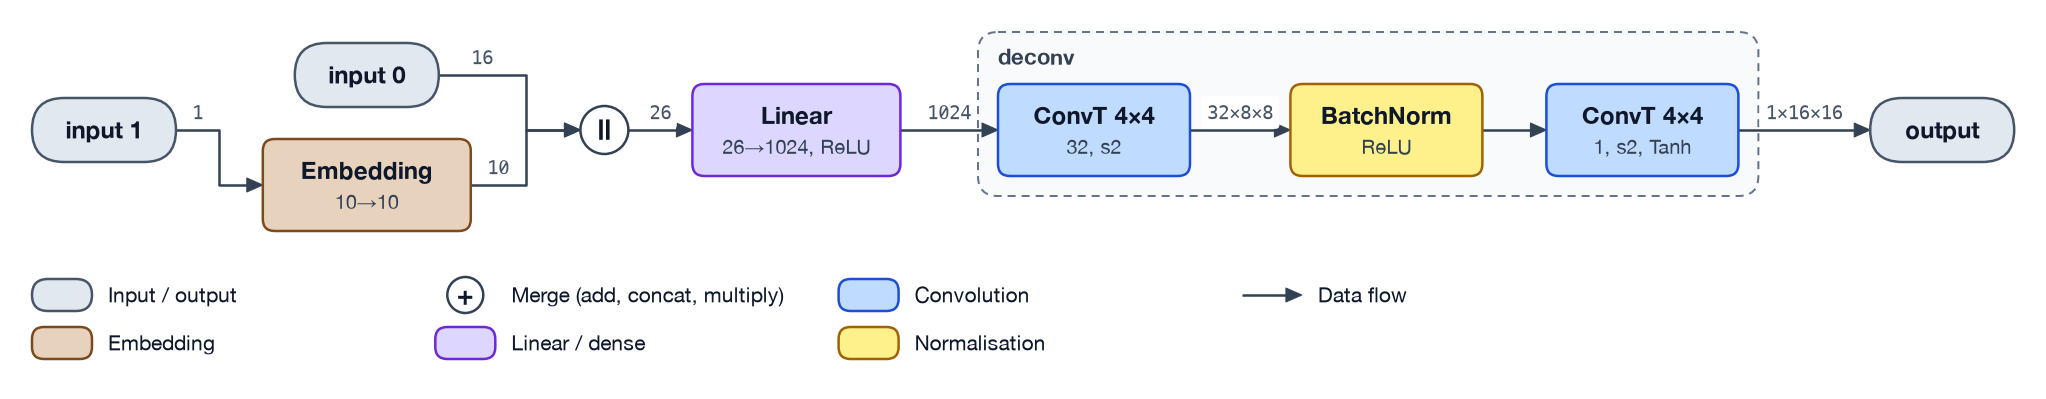

In [12]:
generator, (noise, label) = model("cgan_generator")
tg.draw(generator, (noise, label))  # several inputs: a tuple

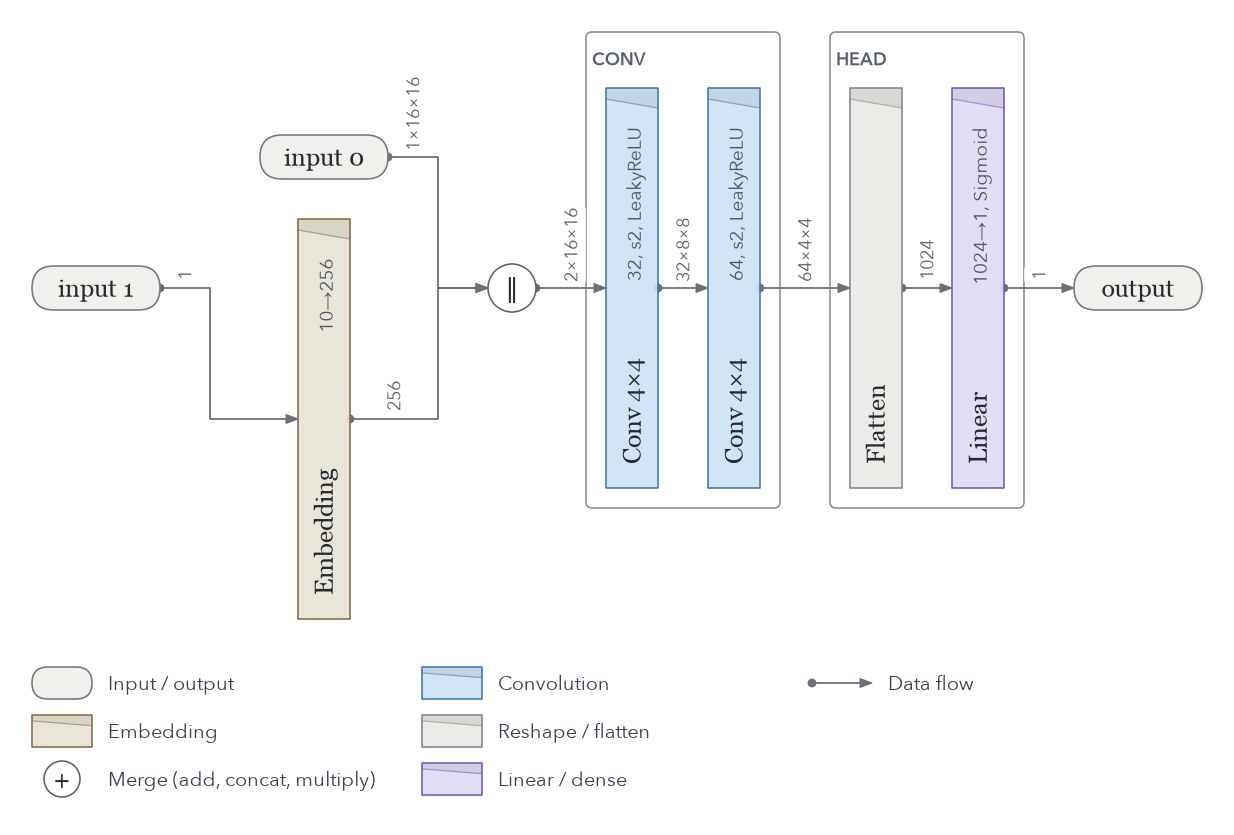

In [13]:
critic, (picture, label) = model("cgan_discriminator")
tg.draw(critic, (picture, label), style="origami")

## Losses and several models in one figure

What no `nn.Module` contains comes in as `annotations`: loss terms (`tg.Loss`), extra inputs
(`tg.Input`) and notes (`tg.Note`). Tensors are named by input/output names or module paths.

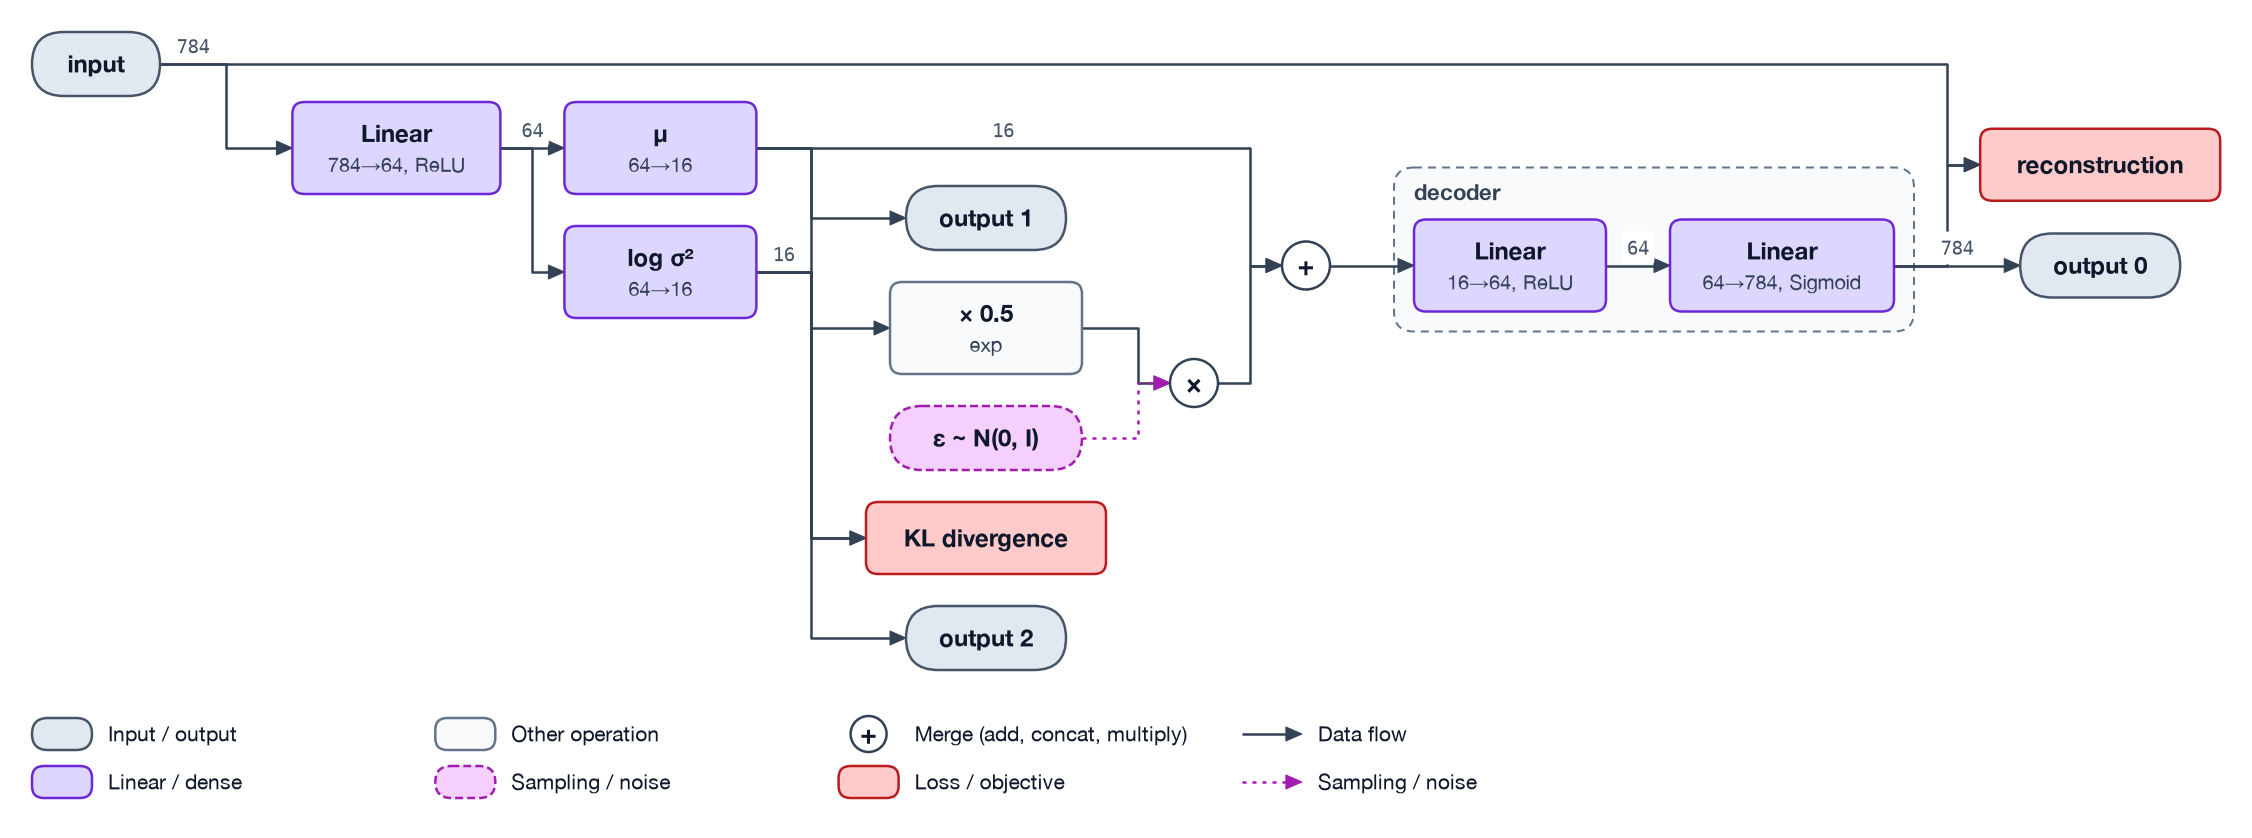

In [14]:
tg.draw(
    vae,
    digits,
    overrides={"mu": {"label": "μ"}, "logvar": {"label": "log σ²"}},
    annotations=[
        tg.Loss("reconstruction", "output 0", "input"),
        tg.Loss("KL divergence", "mu", "logvar"),
    ],
)

Several models: a dict of models and a dict of example inputs, `links` saying which tensor
feeds which model input, and a loss with `trains=` for the dashed arrows of the adversarial
loop. At `level=0` each model is one box.

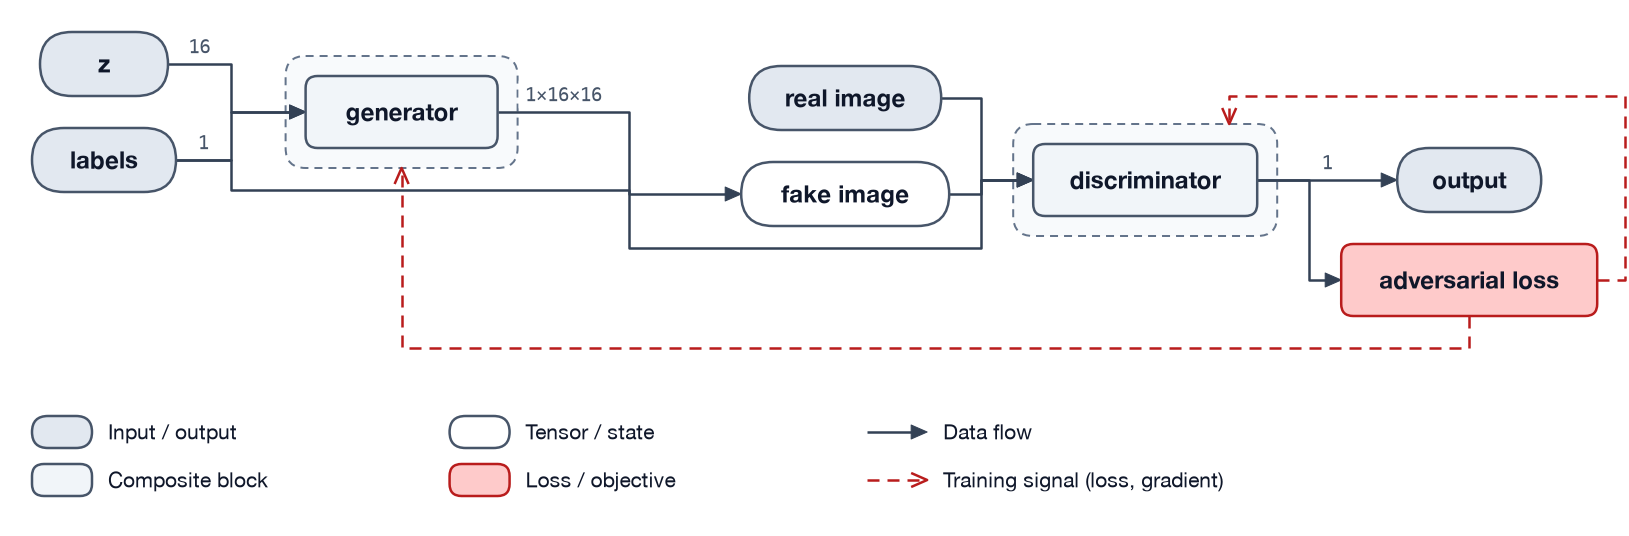

In [15]:
gan = dict(
    links=[
        ("generator", "discriminator.image", "fake image"),  # G's output is what D judges
        ("generator.labels", "discriminator.labels"),  # one condition feeds both
    ],
    annotations=[
        tg.Input("real image", to="discriminator.image"),
        tg.Loss("adversarial loss", "discriminator", trains=["generator", "discriminator"]),
    ],
)
models = {"generator": generator, "discriminator": critic}
inputs = {
    "generator": {"z": noise, "labels": label},
    "discriminator": {"image": picture, "labels": label},
}
tg.draw(models, inputs, level=0, **gan)

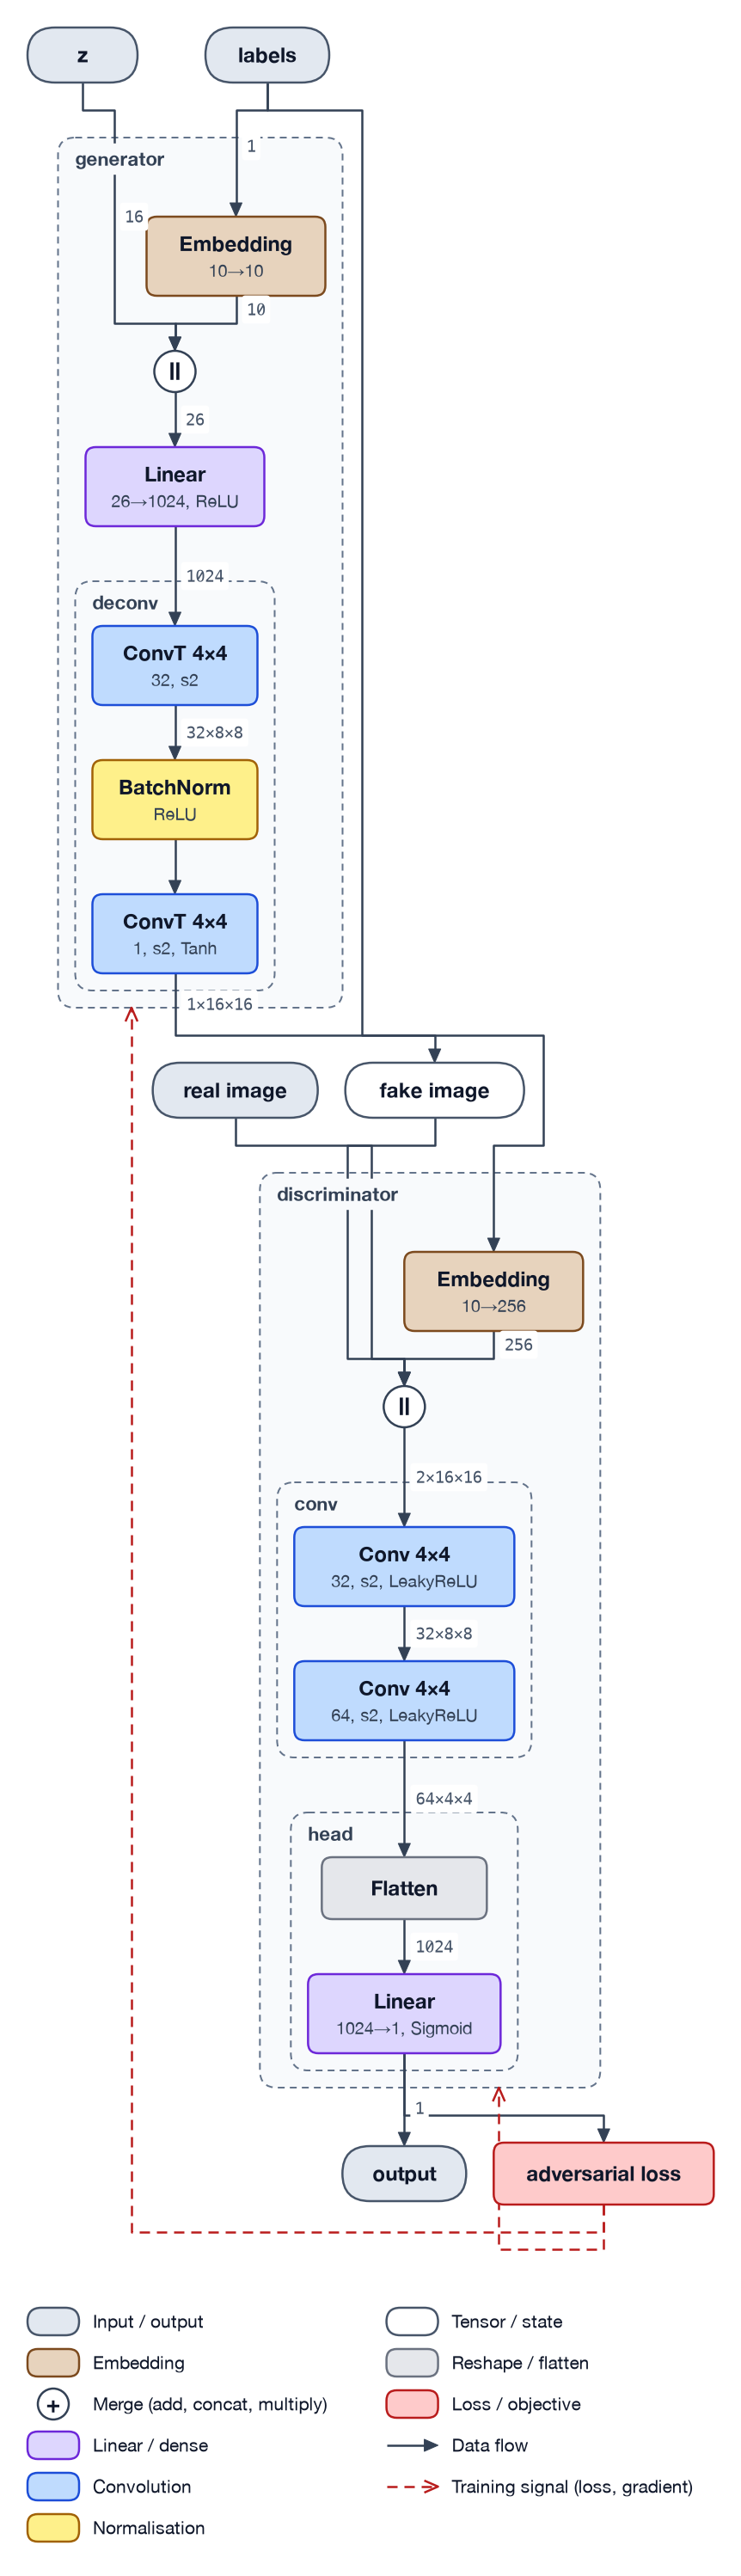

In [16]:
tg.draw(models, inputs, direction="TB", **gan)  # layer by layer

## Transformer encoder, top to bottom

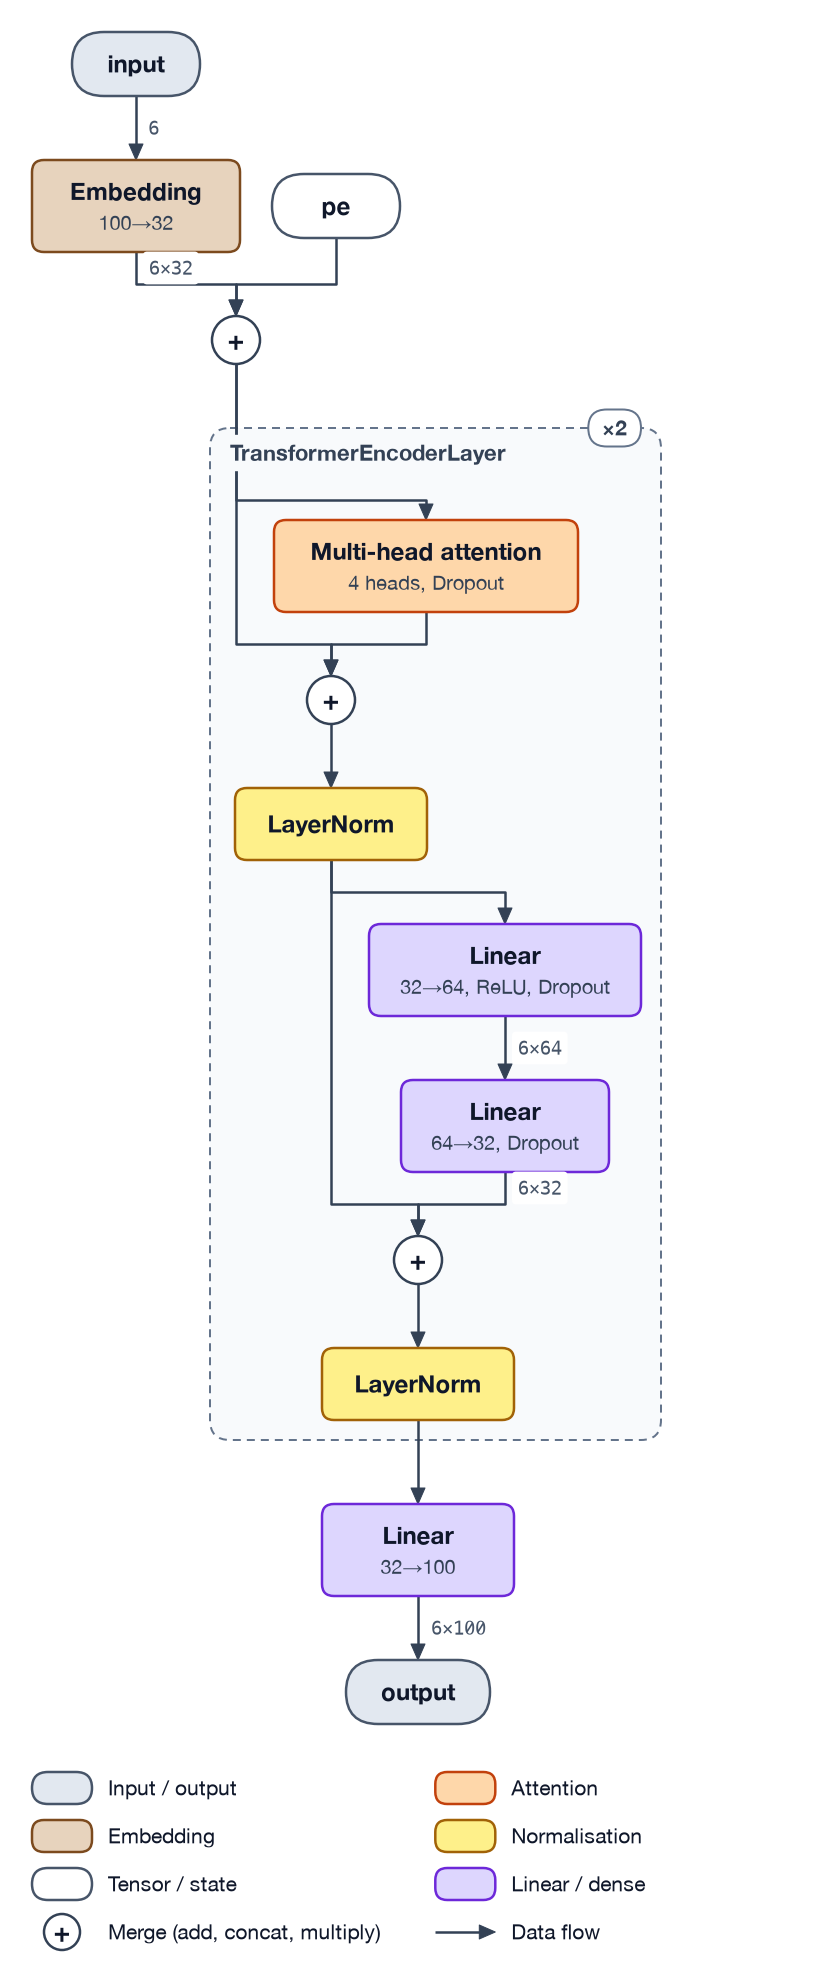

In [17]:
transformer, tokens = model("transformer")
tg.draw(transformer, tokens, direction="TB")

## The same model in the three styles

`default`, `origami` (upright cards, left → right) and `origami-extended` (flat cards, top →
bottom).

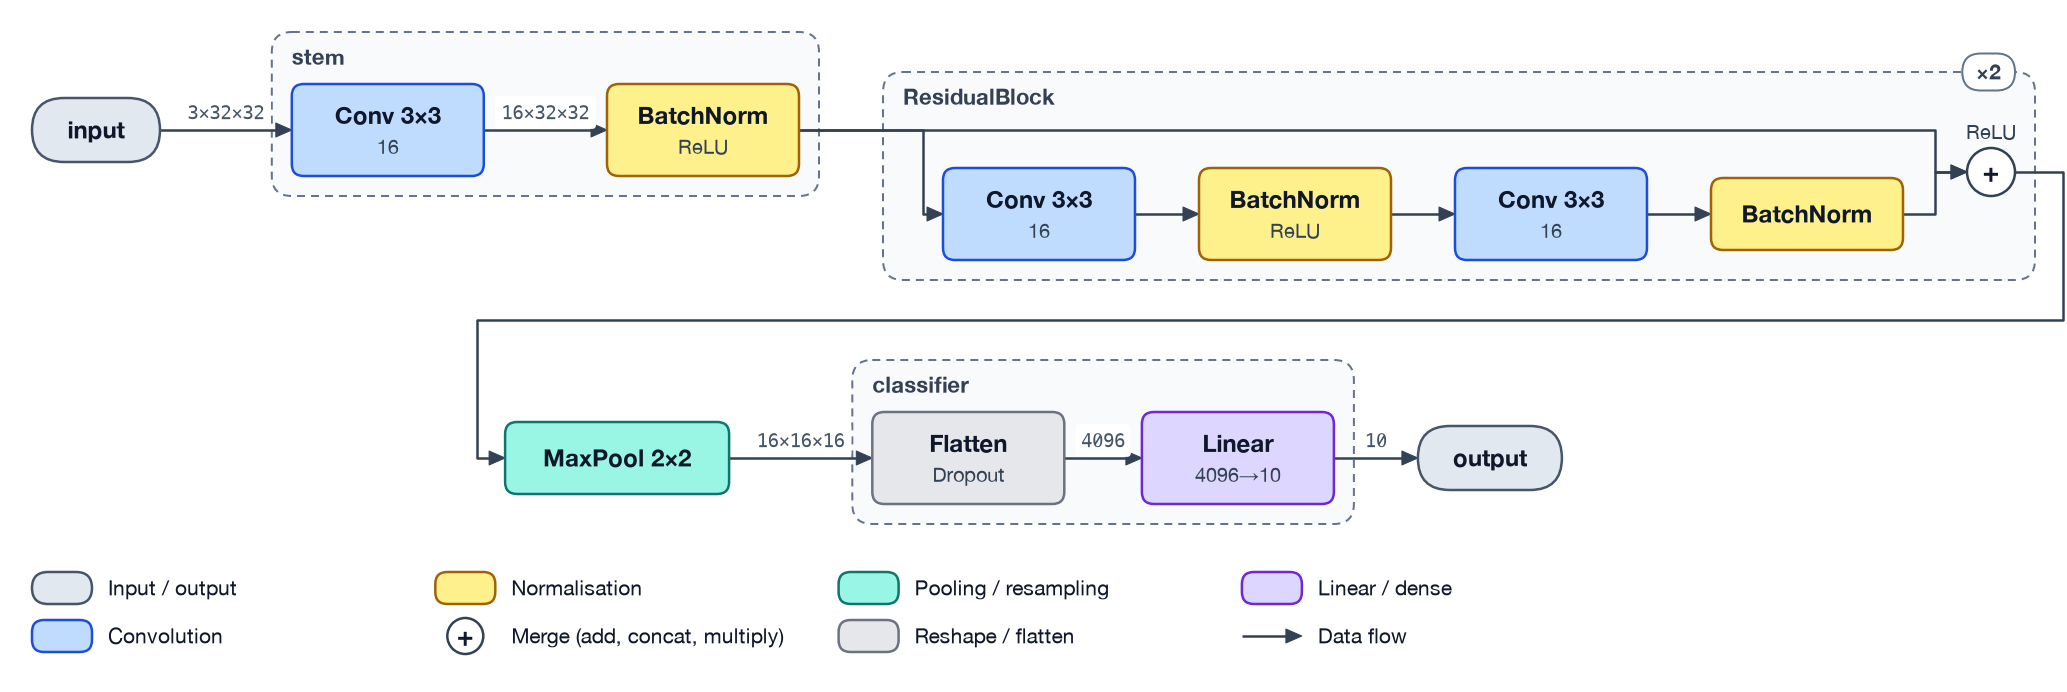

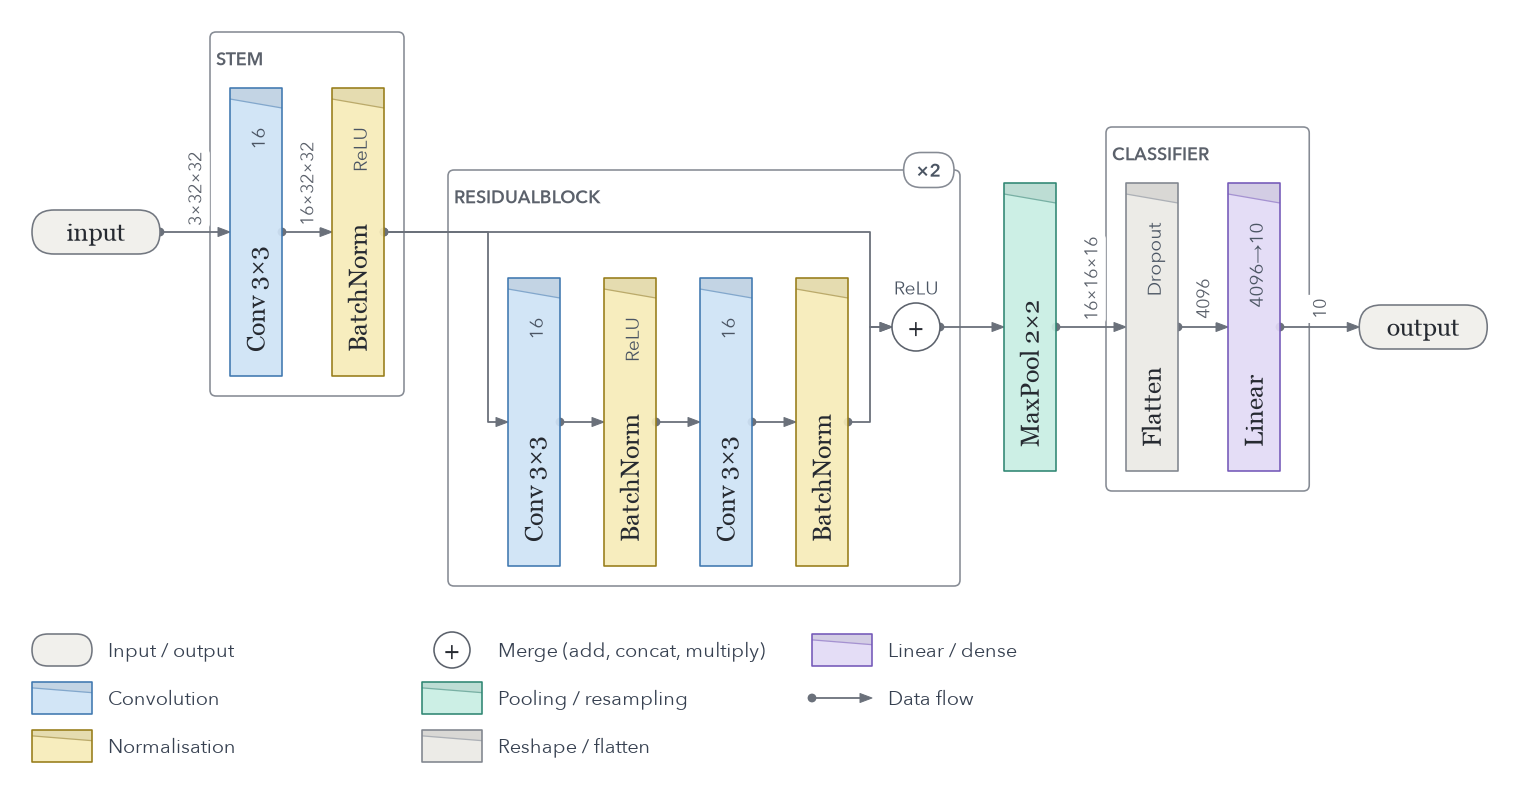

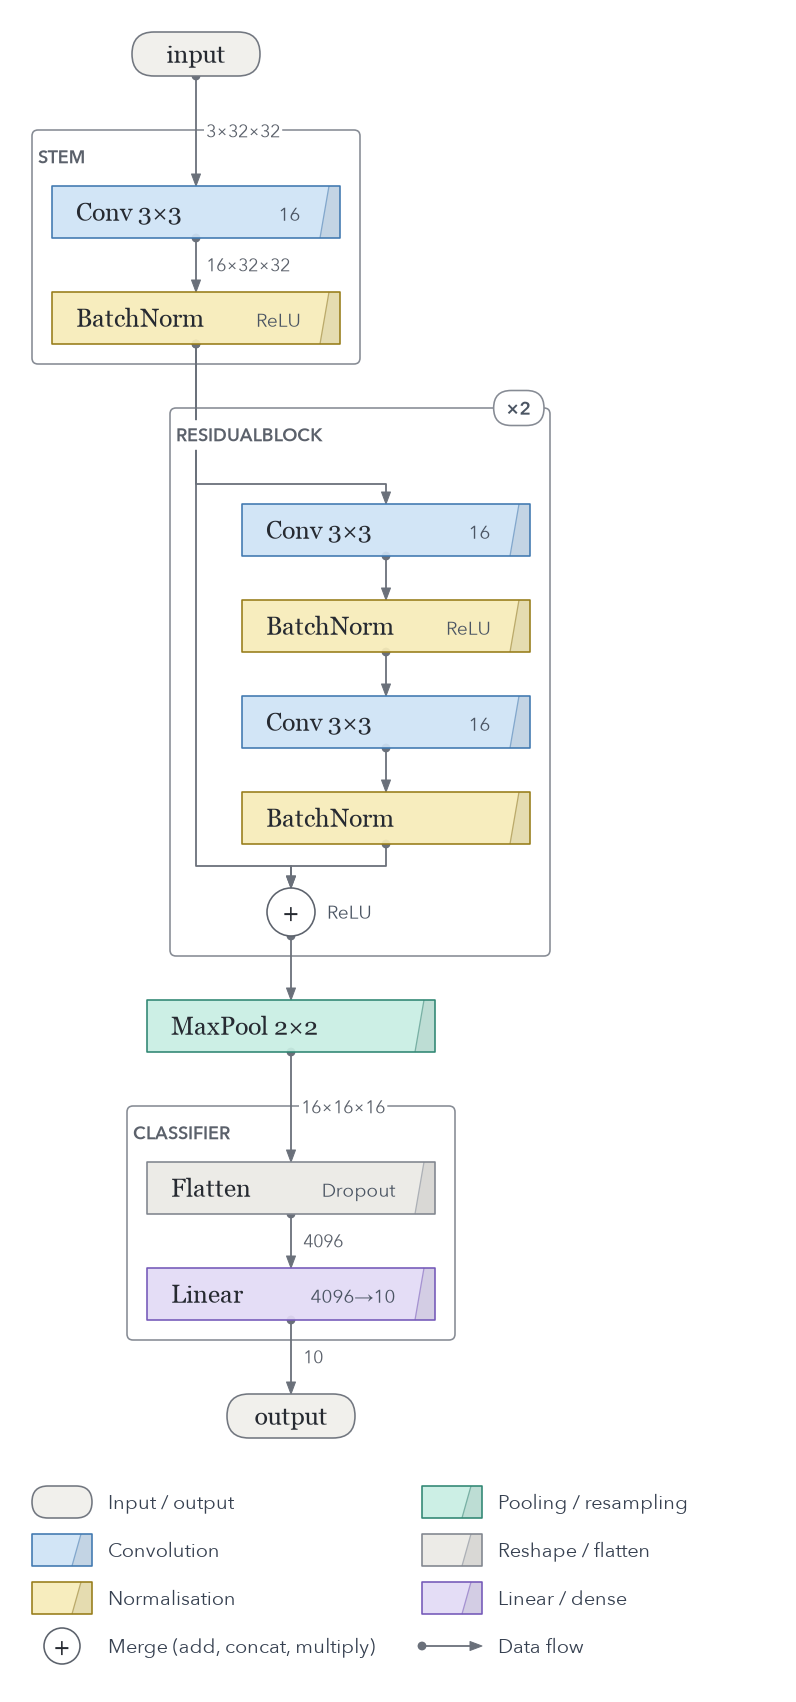

In [18]:
for style in ("default", "origami", "origami-extended"):
    display(tg.draw(cnn, image, style=style))

## Your own names and categories

`overrides` set the label, category or leaf-ness of a module, by path or class name.

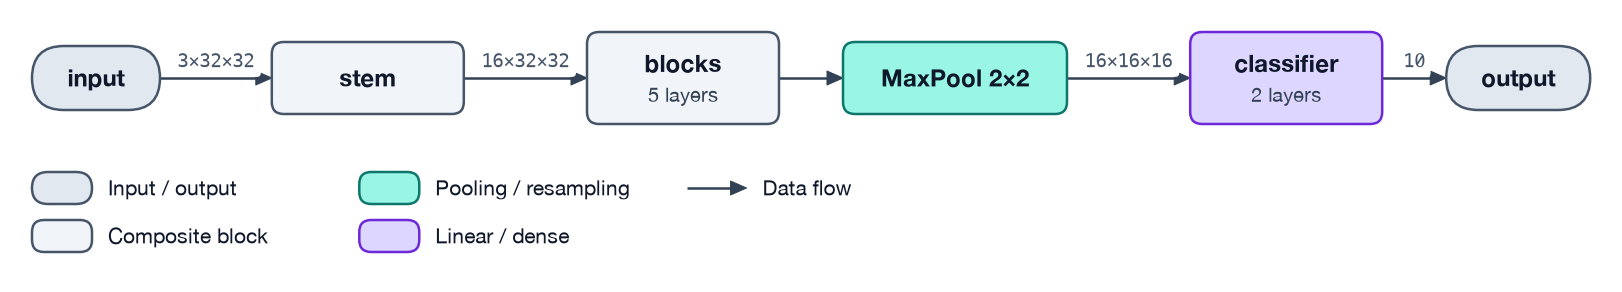

In [19]:
tg.draw(
    cnn,
    image,
    overrides={"classifier.2": {"label": "logits"}, "stem": {"label": "stem"}},
    level="stages",
)